# II. Dự đoán giá nhà

In [1]:
# Các thư viện chính được sử dụng trong notebook

import os
import time
import random
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Đã khởi tạo môi trường.")
print("Random seed:", RANDOM_SEED)

Đã khởi tạo môi trường.
Random seed: 42


# 1. Định nghĩa bài toán

Mục tiêu của ứng dụng này là dự đoán **giá bán của một căn nhà tại King County, Washington, Hoa Kỳ** dựa trên các đặc điểm về cấu trúc, vị trí, thời gian và khu vực của bất động sản.

Đây là một **bài toán hồi quy có giám sát (supervised regression)** vì biến mục tiêu `price` là một giá trị số liên tục, không phải một nhãn lớp rời rạc.

### Mục tiêu trong thực tế

Mô hình sau khi huấn luyện có thể hỗ trợ:

- ước lượng sơ bộ giá nhà;
- so sánh các bất động sản có đặc điểm tương tự;
- hỗ trợ quyết định cho người mua, người bán hoặc chuyên viên phân tích bất động sản.

Kết quả dự đoán nên được hiểu là **giá bán ước tính trên thị trường**, không phải là kết quả thẩm định giá chính thức.

### Sự khác biệt với bài toán phân loại tiểu đường

Khác với ứng dụng dự đoán tiểu đường, nơi mô hình dự đoán một nhãn phân loại, ứng dụng này dự đoán một đại lượng tiền tệ liên tục. Vì vậy cần sử dụng các mô hình hồi quy và các chỉ số đánh giá hồi quy như **MAE, MSE, RMSE và \(R^2\)**.

# 2. Nguồn dữ liệu

**Tên bộ dữ liệu:** House Sales in King County, USA  
**Nguồn:** Kaggle  
**Kaggle URL:** https://www.kaggle.com/datasets/harlfoxem/housesalesprediction  
**Tệp sử dụng:** `kc_house_data.csv`

Bộ dữ liệu chứa thông tin các giao dịch bán nhà tại King County, bao gồm khu vực Seattle, trong khoảng thời gian xấp xỉ từ **tháng 5/2014 đến tháng 5/2015**.

Bộ dữ liệu được sử dụng trong notebook có:

- **21.613 quan sát**
- **21 cột ban đầu**
- biến mục tiêu: **`price`**

Mỗi quan sát đại diện cho **một giao dịch bán nhà được ghi nhận**.

Các cột dữ liệu thô mô tả diện tích, số phòng ngủ, số phòng tắm, số tầng, chất lượng, tình trạng, vị trí, năm xây dựng/cải tạo, thông tin khu vực xung quanh, ngày bán và giá bán.

# 3. Tải dữ liệu

Tệp CSV được tải vào một `pandas DataFrame`.

Ở bước này chưa thực hiện làm sạch hay biến đổi dữ liệu. Việc giữ nguyên DataFrame ban đầu giúp các quyết định tiền xử lý sau đó có thể được mô tả, kiểm tra và tái lập rõ ràng.

In [2]:
df_raw = pd.read_csv(r'C:\Users\Dat\Downloads\PTHTTM\DATA\kc_house_data.csv')

print("Đã tải dữ liệu thành công.")
print("Kích thước dữ liệu thô:", df_raw.shape)

df_raw.head()

Đã tải dữ liệu thành công.
Kích thước dữ liệu thô: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.000",3,1.000,1180,5650,1.000,0,0,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,20141209T000000,"538,000.000",3,2.250,2570,7242,2.000,0,0,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,20150225T000000,"180,000.000",2,1.000,770,10000,1.000,0,0,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,20141209T000000,"604,000.000",4,3.000,1960,5000,1.000,0,0,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,20150218T000000,"510,000.000",3,2.000,1680,8080,1.000,0,0,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


# 4. Kiểm tra và tìm hiểu dữ liệu

Trước khi thay đổi dữ liệu, cần thực hiện kiểm tra ban đầu.

Các bước bắt buộc gồm:

- `df.shape`
- `df.head()`
- `df.info()`
- `df.describe()`
- `df.isna().sum()`
- `df.duplicated().sum()`

Mục đích là hiểu cấu trúc bộ dữ liệu, kiểu dữ liệu, phạm vi giá trị, phân bố biến mục tiêu và các vấn đề chất lượng dữ liệu có thể tồn tại trước khi tiền xử lý.

In [3]:
print("Kích thước dữ liệu:")
print(df_raw.shape)

print("\nNăm dòng đầu tiên:")
display(df_raw.head())

print("\nKiểu dữ liệu và số lượng giá trị không null:")
df_raw.info()

print("\nThống kê mô tả:")
display(df_raw.describe(include="all").T)

print("\nGiá trị thiếu:")
display(df_raw.isna().sum().to_frame("so_luong_thieu"))

print("\nSố dòng trùng hoàn toàn:")
print(df_raw.duplicated().sum())

Kích thước dữ liệu:
(21613, 21)

Năm dòng đầu tiên:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.000",3,1.000,1180,5650,1.000,0,0,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,20141209T000000,"538,000.000",3,2.250,2570,7242,2.000,0,0,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,20150225T000000,"180,000.000",2,1.000,770,10000,1.000,0,0,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,20141209T000000,"604,000.000",4,3.000,1960,5000,1.000,0,0,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,20150218T000000,"510,000.000",3,2.000,1680,8080,1.000,0,0,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503



Kiểu dữ liệu và số lượng giá trị không null:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"21,613.000",NaN,NaN,NaN,"4,580,301,520.865","2,876,565,571.312","1,000,102.000","2,123,049,194.000","3,904,930,410.000","7,308,900,445.000","9,900,000,190.000"
date,21613,372,20140623T000000,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"21,613.000",NaN,NaN,NaN,"540,088.142","367,127.196","75,000.000","321,950.000","450,000.000","645,000.000","7,700,000.000"
bedrooms,"21,613.000",NaN,NaN,NaN,3.371,0.930,0.000,3.000,3.000,4.000,33.000
bathrooms,"21,613.000",NaN,NaN,NaN,2.115,0.770,0.000,1.750,2.250,2.500,8.000
sqft_living,"21,613.000",NaN,NaN,NaN,"2,079.900",918.441,290.000,"1,427.000","1,910.000","2,550.000","13,540.000"
sqft_lot,"21,613.000",NaN,NaN,NaN,"15,106.968","41,420.512",520.000,"5,040.000","7,618.000","10,688.000","1,651,359.000"
floors,"21,613.000",NaN,NaN,NaN,1.494,0.540,1.000,1.000,1.500,2.000,3.500
waterfront,"21,613.000",NaN,NaN,NaN,0.008,0.087,0.000,0.000,0.000,0.000,1.000
view,"21,613.000",NaN,NaN,NaN,0.234,0.766,0.000,0.000,0.000,0.000,4.000



Giá trị thiếu:


,so_luong_thieu
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0



Số dòng trùng hoàn toàn:
0


### Nhận xét từ bước kiểm tra ban đầu

Đối với bộ dữ liệu này:

- biến mục tiêu là `price`;
- phần lớn các cột được lưu dưới dạng số trong CSV;
- `date` ban đầu được lưu dưới dạng chuỗi (`object`) nên cần chuyển sang kiểu thời gian;
- `zipcode` được lưu dưới dạng số nhưng về mặt ý nghĩa phải được xem là **biến phân loại về vị trí**, không phải một đại lượng liên tục;
- `id` chỉ là mã định danh và không nên được xem như một đặc trưng số có quan hệ lớn/nhỏ;
- giá trị `0` trong `yr_renovated` là một mã có ý nghĩa rằng căn nhà chưa có năm cải tạo được ghi nhận, chứ không phải một năm dương lịch thông thường.

Các khác biệt về mặt ngữ nghĩa này rất quan trọng vì mô hình Machine Learning chỉ xử lý biểu diễn số. Nếu biểu diễn sai, mô hình có thể học các mối quan hệ không có ý nghĩa thực tế.

# 5. Phân tích chất lượng dữ liệu

Chất lượng dữ liệu được kiểm tra một cách có hệ thống trước khi làm sạch.

Phân tích bao gồm:

1. giá trị thiếu;
2. bản ghi trùng hoàn toàn;
3. `id` bất động sản xuất hiện nhiều lần;
4. giá trị bất khả thi hoặc đáng nghi;
5. giá trị cực trị;
6. kiểu dữ liệu không phù hợp;
7. các cột có kiểu lưu trữ khác với ý nghĩa thực tế của chúng.

Các `id` lặp lại được phân tích riêng với các dòng trùng hoàn toàn vì cùng một căn nhà có thể được bán nhiều lần ở các thời điểm khác nhau.

In [4]:
quality_summary = pd.DataFrame({
    "kieu_du_lieu": df_raw.dtypes.astype(str),
    "gia_tri_thieu": df_raw.isna().sum(),
    "so_gia_tri_khac_nhau": df_raw.nunique()
})

display(quality_summary)

print("Số dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Số ID lặp lại:", df_raw["id"].duplicated().sum())

# Kiểm tra các bản ghi có ID xuất hiện nhiều hơn một lần
repeated_ids = df_raw[df_raw["id"].duplicated(keep=False)].sort_values(["id", "date"])
display(repeated_ids.head(10))

,kieu_du_lieu,gia_tri_thieu,so_gia_tri_khac_nhau
id,int64,0,21436
date,str,0,372
price,float64,0,4028
bedrooms,int64,0,13
bathrooms,float64,0,30
sqft_living,int64,0,1038
sqft_lot,int64,0,9782
floors,float64,0,6
waterfront,int64,0,2
view,int64,0,5


Số dòng trùng hoàn toàn: 0
Số ID lặp lại: 177


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
2496,1000102,20140916T000000,"280,000.000",6,3.000,2400,9373,2.000,0,0,3,7,2400,0,1991,0,98002,47.326,-122.214,2060,7316
2497,1000102,20150422T000000,"300,000.000",6,3.000,2400,9373,2.000,0,0,3,7,2400,0,1991,0,98002,47.326,-122.214,2060,7316
16814,7200179,20141016T000000,"150,000.000",2,1.000,840,12750,1.000,0,0,3,6,840,0,1925,0,98055,47.484,-122.211,1480,6969
16815,7200179,20150424T000000,"175,000.000",2,1.000,840,12750,1.000,0,0,3,6,840,0,1925,0,98055,47.484,-122.211,1480,6969
11433,109200390,20140820T000000,"245,000.000",3,1.750,1480,3900,1.000,0,0,4,7,1480,0,1980,0,98023,47.298,-122.367,1830,6956
11434,109200390,20141020T000000,"250,000.000",3,1.750,1480,3900,1.000,0,0,4,7,1480,0,1980,0,98023,47.298,-122.367,1830,6956
12417,123039336,20140611T000000,"148,000.000",1,1.000,620,8261,1.000,0,0,3,5,620,0,1939,0,98106,47.514,-122.364,1180,8244
12418,123039336,20141208T000000,"244,900.000",1,1.000,620,8261,1.000,0,0,3,5,620,0,1939,0,98106,47.514,-122.364,1180,8244
7792,251300110,20140731T000000,"225,000.000",3,2.250,2510,12013,2.000,0,0,3,8,2510,0,1988,0,98003,47.347,-122.314,1870,8017
7793,251300110,20150114T000000,"358,000.000",3,2.250,2510,12013,2.000,0,0,3,8,2510,0,1988,0,98003,47.347,-122.314,1870,8017


### Nhận xét về chất lượng dữ liệu

Một `id` bất động sản xuất hiện nhiều lần **không đồng nghĩa với một bản ghi bị trùng**. Một căn nhà có thể được bán nhiều lần, vì vậy chỉ nên xóa một dòng khi có đủ bằng chứng cho thấy toàn bộ bản ghi giao dịch đó thực sự bị lặp.

Cột `id` sẽ được loại khỏi tập đặc trưng của mô hình vì giá trị số của mã định danh không mang ý nghĩa khoảng cách hoặc thứ tự đối với bài toán dự đoán giá nhà.

# 6. Phân tích giá trị thiếu

Giá trị thiếu phải được kiểm tra trước khi huấn luyện mô hình.

Ngay cả khi bộ dữ liệu hiện tại không có giá trị `NaN` rõ ràng, pipeline tiền xử lý vẫn sử dụng các bộ điền khuyết (`imputer`). Điều này giúp hệ thống suy luận ổn định hơn nếu dữ liệu người dùng trong tương lai bị thiếu, đồng thời đảm bảo tiền xử lý được lưu cùng pipeline mô hình.

Cần phân biệt:

- **giá trị thiếu thực sự** như `NaN`;
- **mã mang ý nghĩa riêng**, ví dụ `yr_renovated = 0`, biểu thị không có năm cải tạo được ghi nhận chứ không phải một phép đo số bị thiếu.

In [5]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(2)

missing_table = pd.DataFrame({
    "so_luong_thieu": missing,
    "missing_percent": missing_pct
})

display(missing_table)
print("Tổng số ô thiếu rõ ràng:", int(missing.sum()))

,so_luong_thieu,missing_percent
id,0,0.000
date,0,0.000
price,0,0.000
bedrooms,0,0.000
bathrooms,0,0.000
sqft_living,0,0.000
sqft_lot,0,0.000
floors,0,0.000
waterfront,0,0.000
view,0,0.000


Tổng số ô thiếu rõ ràng: 0


### Quyết định xử lý giá trị thiếu

Không xóa dòng nào chỉ vì thiếu dữ liệu khi bộ dữ liệu hiện tại không chứa giá trị thiếu rõ ràng.

Để pipeline có khả năng hoạt động ổn định khi triển khai:

- đặc trưng số sử dụng **median imputation**;
- đặc trưng phân loại sử dụng **most-frequent imputation**.

Các bộ điền khuyết này chỉ được fit trên tập huấn luyện thông qua pipeline của scikit-learn, nhờ đó tránh **data leakage**.

# 7. Phân tích dữ liệu trùng lặp

Phân tích dữ liệu trùng lặp được chia thành hai trường hợp:

1. **dòng bị trùng hoàn toàn** — có thể xem xét xóa;
2. **`id` bất động sản xuất hiện nhiều lần** — có thể là các lần bán hợp lệ khác nhau.

Chỉ tự động xóa các dòng trùng hoàn toàn. Các `id` lặp lại được giữ lại nếu không có bằng chứng cho thấy toàn bộ bản ghi giao dịch là dữ liệu trùng.

In [6]:
complete_duplicate_count = df_raw.duplicated().sum()
repeated_id_count = df_raw["id"].duplicated().sum()

print("Số dòng trùng hoàn toàn:", complete_duplicate_count)
print("Số ID bất động sản lặp lại:", repeated_id_count)

# Xử lý an toàn: chỉ xóa các dòng trùng hoàn toàn
df = df_raw.drop_duplicates().copy()

print("Kích thước sau khi xóa dòng trùng hoàn toàn:", df.shape)

Số dòng trùng hoàn toàn: 0
Số ID bất động sản lặp lại: 177
Kích thước sau khi xóa dòng trùng hoàn toàn: (21613, 21)


# 8. Phân tích giá trị không hợp lệ

Giá trị không hợp lệ là những giá trị không thể xảy ra, không phù hợp với định nghĩa đặc trưng hoặc có dấu hiệu rất đáng nghi.

Bước này khác với phân tích outlier: một outlier có thể là một quan sát hiếm nhưng hợp lệ, trong khi giá trị không hợp lệ thường phản ánh lỗi dữ liệu.

Các kiểm tra gồm:

- `price` không dương;
- diện tích âm hoặc bằng 0 ở những cột không thể có giá trị đó;
- số phòng ngủ/phòng tắm/số tầng âm;
- năm xây dựng bất khả thi;
- năm cải tạo trước năm xây dựng;
- vĩ độ/kinh độ nằm ngoài phạm vi hợp lệ;
- số phòng ngủ quá lớn và có khả năng là lỗi nhập liệu.

In [7]:
invalid_checks = {
    "price <= 0": (df["price"] <= 0).sum(),
    "bedrooms < 0": (df["bedrooms"] < 0).sum(),
    "bathrooms < 0": (df["bathrooms"] < 0).sum(),
    "floors <= 0": (df["floors"] <= 0).sum(),
    "sqft_living <= 0": (df["sqft_living"] <= 0).sum(),
    "sqft_lot <= 0": (df["sqft_lot"] <= 0).sum(),
    "yr_built < 1800": (df["yr_built"] < 1800).sum(),
    "yr_built > 2020": (df["yr_built"] > 2020).sum(),
    "latitude outside [-90, 90]": (~df["lat"].between(-90, 90)).sum(),
    "longitude outside [-180, 180]": (~df["long"].between(-180, 180)).sum(),
    "bedrooms > 20": (df["bedrooms"] > 20).sum()
}

display(pd.Series(invalid_checks, name="so_luong").to_frame())

print("\nCác bản ghi có số phòng ngủ đáng nghi:")
display(df[df["bedrooms"] > 20])

print("\nSố bản ghi bedrooms = 0:", (df["bedrooms"] == 0).sum())
print("Số bản ghi bathrooms = 0:", (df["bathrooms"] == 0).sum())

,so_luong
price <= 0,0
bedrooms < 0,0
bathrooms < 0,0
floors <= 0,0
sqft_living <= 0,0
sqft_lot <= 0,0
yr_built < 1800,0
yr_built > 2020,0
"latitude outside [-90, 90]",0
"longitude outside [-180, 180]",0



Các bản ghi có số phòng ngủ đáng nghi:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
15870,2402100895,20140625T000000,"640,000.000",33,1.750,1620,6000,1.000,0,0,5,7,1040,580,1947,0,98103,47.688,-122.331,1330,4700



Số bản ghi bedrooms = 0: 13
Số bản ghi bathrooms = 0: 10


### Xử lý giá trị không hợp lệ

Bản ghi có **33 phòng ngủ** được xem là một lỗi nhập dữ liệu có khả năng cao vì giá trị này cực kỳ khác biệt so với phần còn lại của bộ dữ liệu nhà ở dân dụng. Bản ghi này được loại trước khi huấn luyện.

Tuy nhiên, các giá trị như `bedrooms = 0` hoặc `bathrooms = 0` **không bị xóa tự động**. Chúng có thể đại diện cho căn studio, bất động sản chưa hoàn thiện, trường hợp đặc biệt hoặc một quy ước mã hóa của bộ dữ liệu. Nếu không có bằng chứng chắc chắn rằng chúng sai, việc xóa sẽ tạo ra một giả định chủ quan.

Tương tự, `yr_renovated = 0` được giữ lại như một mã có ý nghĩa “chưa cải tạo / không có năm cải tạo được ghi nhận” và sau đó được chuyển thành các đặc trưng cải tạo rõ ràng hơn.

In [8]:
# Chỉ loại bản ghi có số phòng ngủ cực đoan và rõ ràng đáng nghi.
df = df[df["bedrooms"] <= 20].copy()

print("Kích thước sau khi xử lý giá trị không hợp lệ:", df.shape)
print("Số phòng ngủ lớn nhất sau khi làm sạch:", df["bedrooms"].max())

Kích thước sau khi xử lý giá trị không hợp lệ: (21612, 21)
Số phòng ngủ lớn nhất sau khi làm sạch: 11


# 9. Phân tích ngoại lệ (Outlier)

Các giá trị ngoại lệ được phân tích bằng phương pháp khoảng tứ phân vị (**IQR**) kết hợp với trực quan hóa.

Nguyên tắc quan trọng:

> Phát hiện outlier không đồng nghĩa với việc phải tự động xóa outlier.

Những căn nhà hạng sang, lô đất rất lớn hoặc mức giá rất cao có thể hoàn toàn hợp lệ và là một phần thực tế của thị trường. Nếu xóa chúng một cách máy móc, mô hình có thể mất khả năng dự đoán cho những bất động sản đắt tiền hoặc khác biệt.

Vì vậy, bước này dùng để xác định và phân tích các giá trị cực trị; chỉ loại bỏ quan sát khi có lý do rõ ràng để kết luận rằng đó là dữ liệu không hợp lệ.

In [9]:
outlier_cols = [
    "price", "bedrooms", "bathrooms", "sqft_living",
    "sqft_lot", "floors", "sqft_above", "sqft_basement"
]

outlier_report = []

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_report.append({
        "dac_trung": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "so_luong_outlier": int(count),
        "ty_le_outlier": round(count / len(df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
display(outlier_report)

,dac_trung,Q1,Q3,IQR,lower_bound,upper_bound,so_luong_outlier,ty_le_outlier
0,price,"321,837.500","645,000.000","323,162.500","-162,906.250","1,129,743.750",1146,5.300
1,bedrooms,3.000,4.000,1.000,1.500,5.500,545,2.520
2,bathrooms,1.750,2.500,0.750,0.625,3.625,571,2.640
3,sqft_living,"1,426.500","2,550.000","1,123.500",-258.750,"4,235.250",572,2.650
4,sqft_lot,"5,040.000","10,688.250","5,648.250","-3,432.375","19,160.625",2425,11.220
5,floors,1.000,2.000,1.000,-0.500,3.500,0,0.000
6,sqft_above,"1,190.000","2,210.000","1,020.000",-340.000,"3,740.000",611,2.830
7,sqft_basement,0.000,560.000,560.000,-840.000,"1,400.000",496,2.300


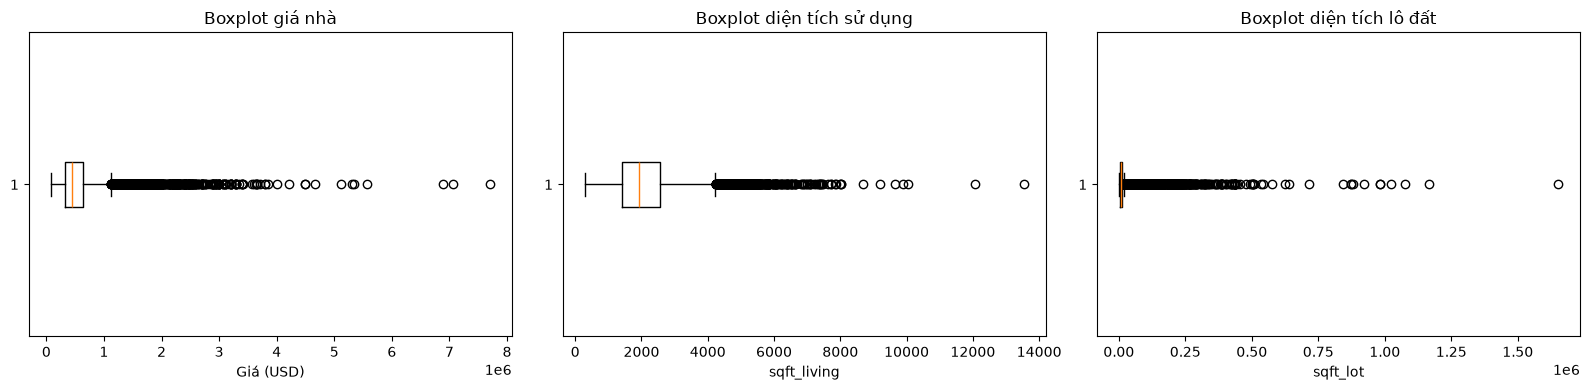

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].boxplot(df["price"], vert=False)
axes[0].set_title("Boxplot giá nhà")
axes[0].set_xlabel("Giá (USD)")

axes[1].boxplot(df["sqft_living"], vert=False)
axes[1].set_title("Boxplot diện tích sử dụng")
axes[1].set_xlabel("sqft_living")

axes[2].boxplot(df["sqft_lot"], vert=False)
axes[2].set_title("Boxplot diện tích lô đất")
axes[2].set_xlabel("sqft_lot")

plt.tight_layout()
plt.show()

### Quyết định xử lý outlier

Quy tắc IQR đánh dấu nhiều bất động sản có giá trị cao hoặc diện tích lớn là outlier vì các biến bất động sản có phân bố lệch phải mạnh.

Do đó:

- các căn nhà có giá cao nhưng hợp lệ được giữ lại;
- diện tích nhà/diện tích lô đất lớn được giữ lại nếu không có bằng chứng độc lập rằng đó là lỗi;
- bản ghi `bedrooms = 33` đã được xử lý ở bước giá trị không hợp lệ thay vì sử dụng quy tắc cắt outlier chung.

Cách xử lý này giúp giữ lại biến thiên thực tế của thị trường và tránh làm cho phạm vi học của mô hình bị thu hẹp một cách nhân tạo.

# 10. Phân tích khám phá dữ liệu (EDA)

Phần EDA của bài toán dự đoán giá nhà bao gồm:

- phân bố giá nhà;
- phân bố các đặc trưng quan trọng;
- mối quan hệ giữa đặc trưng và giá;
- phân tích tương quan;
- các mẫu liên quan đến vị trí địa lý;
- hành vi của các giá trị ngoại lệ.

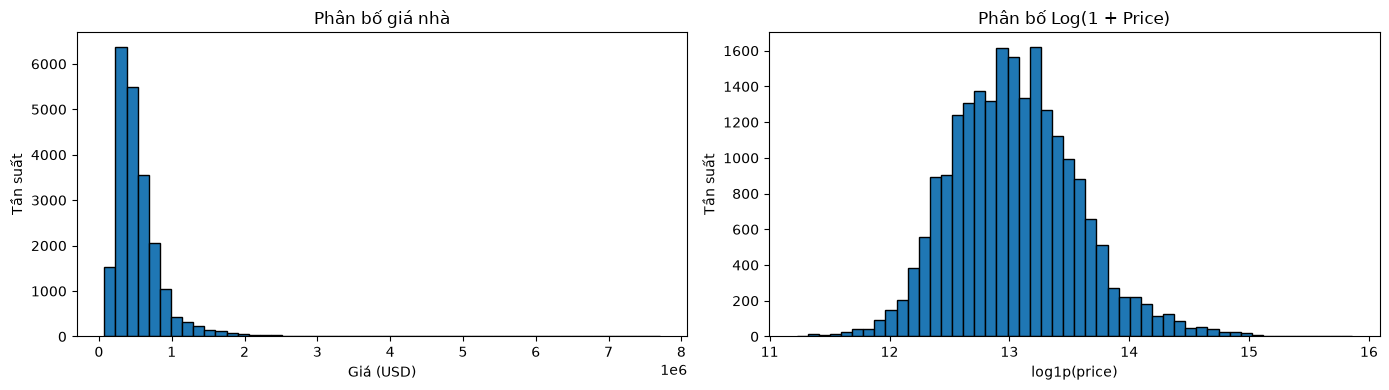

Độ lệch của price: 4.024
Độ lệch của log1p(price): 0.428


In [11]:
# Phân bố biến mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df["price"], bins=50, edgecolor="black")
axes[0].set_title("Phân bố giá nhà")
axes[0].set_xlabel("Giá (USD)")
axes[0].set_ylabel("Tần suất")

axes[1].hist(np.log1p(df["price"]), bins=50, edgecolor="black")
axes[1].set_title("Phân bố Log(1 + Price)")
axes[1].set_xlabel("log1p(price)")
axes[1].set_ylabel("Tần suất")

plt.tight_layout()
plt.show()

print("Độ lệch của price:", round(df["price"].skew(), 3))
print("Độ lệch của log1p(price):", round(np.log1p(df["price"]).skew(), 3))

### Diễn giải EDA - phân bố biến mục tiêu

**Quan sát:** Giá nhà có phân bố lệch phải mạnh. Phần lớn giao dịch tập trung ở vùng giá trung bình, trong khi một số ít căn nhà có mức giá rất cao.

**Diễn giải:** Thị trường King County có phần đuôi dài ở phía giá cao, nhiều khả năng phản ánh các bất động sản hạng sang hoặc có vị trí đặc biệt.

**Hàm ý đối với ML:** RMSE sẽ nhạy với các sai số lớn ở nhóm nhà đắt tiền. Các mô hình tuyến tính cũng có thể gặp khó khăn trước quan hệ phi tuyến và phương sai sai số thay đổi, vì vậy cần so sánh thêm các mô hình ensemble dựa trên cây.

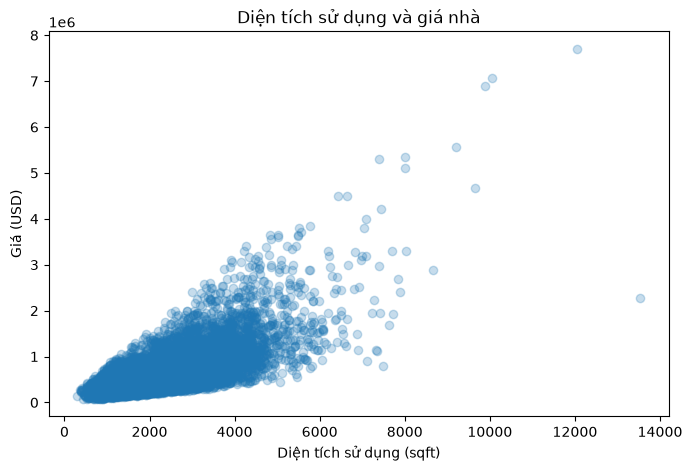

In [12]:
# Mối quan hệ giữa diện tích sử dụng và giá
plt.figure(figsize=(8, 5))
plt.scatter(df["sqft_living"], df["price"], alpha=0.25)
plt.xlabel("Diện tích sử dụng (sqft)")
plt.ylabel("Giá (USD)")
plt.title("Diện tích sử dụng và giá nhà")
plt.show()

### Diễn giải EDA - diện tích sử dụng và giá

**Quan sát:** Nhìn chung, diện tích sử dụng (`sqft_living`) càng lớn thì giá bán càng cao, nhưng mối quan hệ không hoàn toàn tuyến tính và mức độ phân tán tăng ở các căn nhà lớn.

**Diễn giải:** `sqft_living` có khả năng là một đặc trưng dự đoán quan trọng, nhưng giá nhà còn phụ thuộc vào chất lượng, vị trí, tình trạng waterfront và nhiều đặc trưng khác.

**Hàm ý đối với ML:** Các mô hình có khả năng học tương tác và quan hệ phi tuyến có thể hoạt động tốt hơn Linear Regression thuần túy.

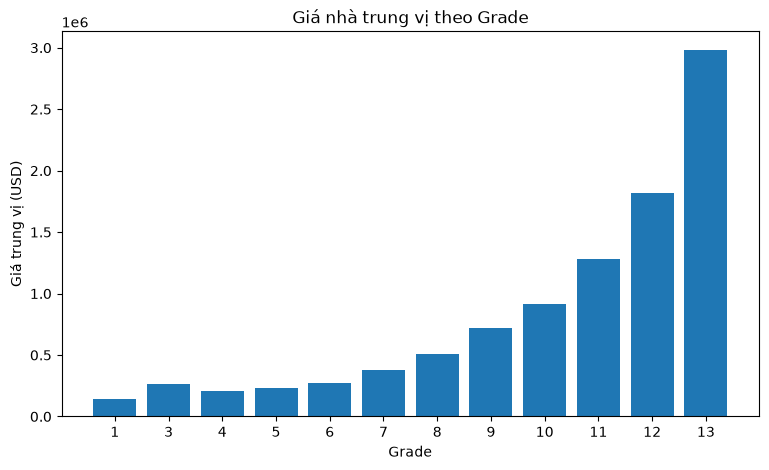

In [13]:
# Giá theo grade
grade_price = df.groupby("grade")["price"].median()

plt.figure(figsize=(9, 5))
plt.bar(grade_price.index.astype(str), grade_price.values)
plt.xlabel("Grade")
plt.ylabel("Giá trung vị (USD)")
plt.title("Giá nhà trung vị theo Grade")
plt.show()

### Diễn giải EDA - `grade` và giá

**Quan sát:** Giá bán trung vị tăng rõ rệt khi `grade` tăng.

**Diễn giải:** Chất lượng xây dựng và thiết kế có mối liên hệ mạnh với giá trị thị trường.

**Hàm ý đối với ML:** `grade` nên được giữ lại làm đặc trưng dự đoán. Mặc dù được lưu dưới dạng số, biến này có bản chất là một thang chất lượng có thứ tự nên có thể biểu diễn dưới dạng đặc trưng số thứ tự.

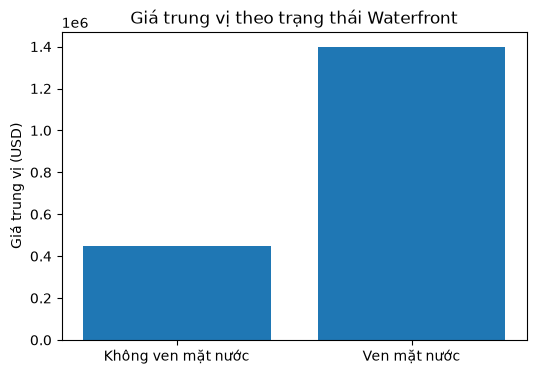

In [14]:
# Ảnh hưởng của waterfront
waterfront_price = df.groupby("waterfront")["price"].median()

plt.figure(figsize=(6, 4))
plt.bar(["Không ven mặt nước", "Ven mặt nước"], waterfront_price.values)
plt.ylabel("Giá trung vị (USD)")
plt.title("Giá trung vị theo trạng thái Waterfront")
plt.show()

### Diễn giải EDA - waterfront

**Quan sát:** Các bất động sản có vị trí ven mặt nước có giá bán trung vị cao hơn đáng kể.

**Diễn giải:** Việc tiếp giáp mặt nước là một tín hiệu mạnh về vị trí và tiện ích của bất động sản.

**Hàm ý đối với ML:** Đặc trưng nhị phân `waterfront` nên được giữ lại. Các mô hình phi tuyến có thể học thêm tương tác giữa `waterfront`, `grade`, `view` và vị trí.

,tuong_quan_voi_price
price,1.000
sqft_living,0.702
grade,0.667
sqft_above,0.606
sqft_living15,0.585
bathrooms,0.525
view,0.397
sqft_basement,0.324
bedrooms,0.315
lat,0.307


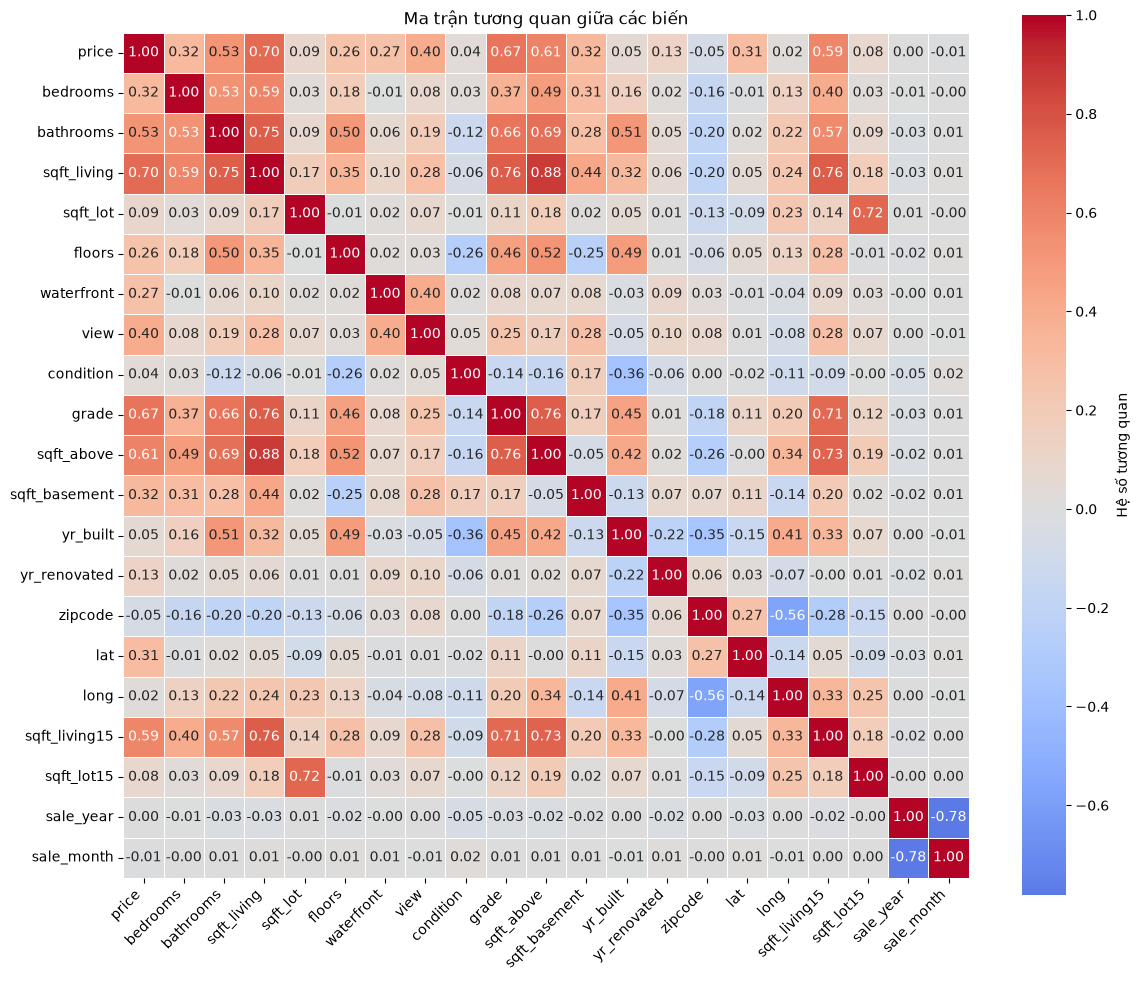

In [38]:
# Phân tích tương quan cho các biến số
import seaborn as sns
import matplotlib.pyplot as plt

corr_df = df.drop(columns=["id"]).copy()

corr_df["date"] = pd.to_datetime(
    corr_df["date"],
    format="%Y%m%dT%H%M%S"
)

corr_df["sale_year"] = corr_df["date"].dt.year
corr_df["sale_month"] = corr_df["date"].dt.month

corr_df = corr_df.drop(columns=["date"])

# Ma trận tương quan
corr = corr_df.corr(numeric_only=True)

# Tương quan với price
price_corr = corr["price"].sort_values(ascending=False)
display(price_corr.to_frame("tuong_quan_voi_price"))

# Vẽ heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Hệ số tương quan"}
)

plt.title("Ma trận tương quan giữa các biến")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Diễn giải EDA - tương quan

**Quan sát:** Các biến như diện tích sử dụng, `grade`, diện tích phía trên mặt đất, số phòng tắm và diện tích sử dụng của các căn nhà lân cận thường có tương quan dương với `price` mạnh hơn nhiều biến khác.

**Diễn giải:** Diện tích và chất lượng nhà rất quan trọng, nhưng hệ số tương quan đơn lẻ không thể mô tả đầy đủ ảnh hưởng của vị trí, tương tác giữa các biến, ngưỡng hay quan hệ phi tuyến.

**Hàm ý đối với ML:** Tương quan hữu ích để hiểu dữ liệu nhưng không nên là tiêu chí duy nhất để lựa chọn đặc trưng. Vì vậy notebook vẫn so sánh các mô hình ensemble có khả năng học quan hệ phức tạp hơn.

# 11. Các loại đặc trưng

Kiểu dữ liệu được lưu trong CSV không phải lúc nào cũng là kiểu biểu diễn phù hợp cho Machine Learning.

## Biến mục tiêu

- `price` — biến số liên tục cần dự đoán.

## Biến định danh bị loại

- `id` — mã định danh bất động sản; bị loại vì giá trị số của nó không mang ý nghĩa định lượng đối với giá nhà.

## Biến thời gian

- `date` — được chuyển sang kiểu thời gian và tách thành `sale_year`, `sale_month`.

## Biến phân loại

- `zipcode` — được lưu dưới dạng số nguyên nhưng được xem là **biến phân loại danh nghĩa về vị trí**.
  - Chênh lệch như 98101 − 98001 không thể hiện một khoảng cách địa lý có ý nghĩa.
  - Vì vậy biến này được chuyển sang chuỗi và mã hóa one-hot.

## Biến nhị phân / thứ tự / số

Ví dụ:

- `waterfront` — nhị phân;
- `view` — điểm số có thứ tự;
- `condition` — mức tình trạng có thứ tự;
- `grade` — mức chất lượng có thứ tự;
- `bedrooms`, `bathrooms`, `floors` — các đại lượng đếm;
- các biến diện tích — biến số;
- `lat`, `long` — tọa độ địa lý.

`yr_renovated` cần xử lý riêng vì giá trị `0` mang ý nghĩa chưa có cải tạo được ghi nhận.

In [16]:
feature_type_table = pd.DataFrame({
    "dac_trung": df.columns,
    "kieu_du_lieu_goc": df.dtypes.astype(str).values,
    "vai_tro": [
        "định danh - loại bỏ",          # id
        "thời gian - biến đổi",         # date
        "biến mục tiêu",                       # price
        "biến số",                    # bedrooms
        "biến số",                    # bathrooms
        "biến số",                    # sqft_living
        "biến số",                    # sqft_lot
        "biến số",                    # floors
        "nhị phân",                       # waterfront
        "thứ tự",                      # view
        "thứ tự",                      # condition
        "thứ tự",                      # grade
        "biến số",                    # sqft_above
        "biến số",                    # sqft_basement
        "năm - tạo đặc trưng",              # yr_built
        "năm/mã ngữ nghĩa - tạo đặc trưng",# yr_renovated
        "phân loại - one-hot",         # zipcode
        "biến số",                    # lat
        "biến số",                    # long
        "biến số",                    # sqft_living15
        "biến số"                     # sqft_lot15
    ]
})

display(feature_type_table)

,dac_trung,kieu_du_lieu_goc,vai_tro
0,id,int64,định danh - loại bỏ
1,date,str,thời gian - biến đổi
2,price,float64,biến mục tiêu
3,bedrooms,int64,biến số
4,bathrooms,float64,biến số
5,sqft_living,int64,biến số
6,sqft_lot,int64,biến số
7,floors,float64,biến số
8,waterfront,int64,nhị phân
9,view,int64,thứ tự


# 12. Biểu diễn dữ liệu

Đây là phần kết nối trung tâm giữa dữ liệu thực tế và mô hình tính toán.

In [17]:
# Ví dụ: một bản ghi gốc trước khi tạo đặc trưng
raw_example = df.iloc[[0]].copy()
display(raw_example)

print("Kích thước DataFrame thô:", df.shape)
print("Kiểu dữ liệu gốc của target:", df["price"].dtype)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.000",3,1.000,1180,5650,1.000,0,0,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650


Kích thước DataFrame thô: (21612, 21)
Kiểu dữ liệu gốc của target: float64


# 13. Kỹ thuật tạo đặc trưng

Feature engineering chuyển các giá trị thô thành những đặc trưng có ý nghĩa hơn và thuận lợi cho việc triển khai.

Các biến đổi được sử dụng:

1. chuyển `date` sang kiểu thời gian;
2. tách `sale_year`;
3. tách `sale_month`;
4. tính `house_age = sale_year - yr_built`;
5. tạo biến chỉ báo `renovated`;
6. tính `years_since_renovation` nếu căn nhà đã được cải tạo;
7. chuyển `zipcode` sang chuỗi để mã hóa phân loại;
8. loại `id`;
9. loại các cột gốc `date`, `yr_built`, `yr_renovated` sau khi thông tin của chúng đã được biểu diễn qua các đặc trưng mới.

Các biến đổi được đóng gói trong hàm dùng lại để cùng một logic ngữ nghĩa có thể được áp dụng trong giai đoạn inference.

In [18]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    # Chuyển đổi ngày bán
    data["date"] = pd.to_datetime(
        data["date"],
        format="%Y%m%dT%H%M%S",
        errors="coerce"
    )

    # Đặc trưng thời gian
    data["sale_year"] = data["date"].dt.year
    data["sale_month"] = data["date"].dt.month

    # Tuổi căn nhà tại thời điểm bán
    data["house_age"] = data["sale_year"] - data["yr_built"]

    # Biểu diễn thông tin cải tạo
    data["renovated"] = (data["yr_renovated"] > 0).astype(int)

    data["years_since_renovation"] = np.where(
        data["yr_renovated"] > 0,
        data["sale_year"] - data["yr_renovated"],
        0
    )

    # Zipcode là biến phân loại, không phải biến liên tục
    data["zipcode"] = data["zipcode"].astype(str)

    # Loại mã định danh và các cột gốc đã được biểu diễn bởi đặc trưng mới
    data = data.drop(
        columns=["id", "date", "yr_built", "yr_renovated"],
        errors="ignore"
    )

    return data


df_model = engineer_features(df)

print("Kích thước sau feature engineering:", df_model.shape)
display(df_model.head())

Kích thước sau feature engineering: (21612, 22)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,years_since_renovation
0,"221,900.000",3,1.000,1180,5650,1.000,0,0,3,7,1180,0,98178,47.511,-122.257,1340,5650,2014,10,59,0,0
1,"538,000.000",3,2.250,2570,7242,2.000,0,0,3,7,2170,400,98125,47.721,-122.319,1690,7639,2014,12,63,1,23
2,"180,000.000",2,1.000,770,10000,1.000,0,0,3,6,770,0,98028,47.738,-122.233,2720,8062,2015,2,82,0,0
3,"604,000.000",4,3.000,1960,5000,1.000,0,0,5,7,1050,910,98136,47.521,-122.393,1360,5000,2014,12,49,0,0
4,"510,000.000",3,2.000,1680,8080,1.000,0,0,3,8,1680,0,98074,47.617,-122.045,1800,7503,2015,2,28,0,0


In [19]:
# Tách biến mục tiêu khỏi các đặc trưng đầu vào
X = df_model.drop(columns=["price"]).copy()
y = df_model["price"].copy()

categorical_features = ["zipcode"]
numerical_features = [c for c in X.columns if c not in categorical_features]

print("Các đặc trưng số:")
print(numerical_features)

print("\nCác đặc trưng phân loại:")
print(categorical_features)

print("\nKích thước X trước khi mã hóa:", X.shape)
print("Kích thước y:", y.shape)

Các đặc trưng số:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'renovated', 'years_since_renovation']

Các đặc trưng phân loại:
['zipcode']

Kích thước X trước khi mã hóa: (21612, 21)
Kích thước y: (21612,)


# 14. Chia tập train/validation/test

Để quá trình phát triển và đánh giá cuối cùng độc lập với nhau, dữ liệu được chia thành:

- **70% tập huấn luyện (training)**
- **15% tập validation**
- **15% tập test**

Vai trò của từng tập:

- **training set** — fit các bước tiền xử lý và tham số của mô hình;
- **validation set** — so sánh các mô hình ứng viên và lựa chọn mô hình cuối cùng;
- **test set** — chỉ sử dụng một lần để đánh giá cuối cùng một cách khách quan.

Dữ liệu test không được ảnh hưởng đến việc fit scaler, encoder, imputer, huấn luyện mô hình hoặc lựa chọn mô hình.

Một `random seed` cố định được sử dụng để đảm bảo khả năng tái lập kết quả.

In [20]:
# Lần chia thứ nhất: 70% train, 30% tạm thời
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_SEED
)

# Lần chia thứ hai: chia đều phần tạm thời -> 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED
)

print("Tập training:", X_train.shape, y_train.shape)
print("Tập validation:", X_val.shape, y_val.shape)
print("Tập test:", X_test.shape, y_test.shape)

print("\nTỷ lệ xấp xỉ:")
print("Train:", round(len(X_train) / len(X), 3))
print("Validation:", round(len(X_val) / len(X), 3))
print("Test:", round(len(X_test) / len(X), 3))

Tập training: (15128, 21) (15128,)
Tập validation: (3242, 21) (3242,)
Tập test: (3242, 21) (3242,)

Tỷ lệ xấp xỉ:
Train: 0.7
Validation: 0.15
Test: 0.15


# 15. Pipeline tiền xử lý

Pipeline tiền xử lý được fit **chỉ trên tập huấn luyện**.

## Đặc trưng số

Quy trình:

\[
\text{median imputation} \rightarrow \text{standardization}
\]

Median imputation ít bị ảnh hưởng bởi các biến lệch và giúp pipeline triển khai xử lý được trường hợp đầu vào số bị thiếu.

## Đặc trưng phân loại

Quy trình:

\[
\text{most-frequent imputation} \rightarrow \text{one-hot encoding}
\]

`handle_unknown="ignore"` giúp inference vẫn hoạt động nếu xuất hiện một `zipcode` chưa từng có trong dữ liệu dùng để fit encoder.

Tất cả phép biến đổi được đặt trong `ColumnTransformer`, sau đó được nhúng vào pipeline của từng mô hình. Điều này đảm bảo quá trình huấn luyện và suy luận sử dụng chính xác cùng một logic tiền xử lý.

In [21]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit một bản sao tạm thời chỉ để minh họa shape của biểu diễn dữ liệu.
representation_preprocessor = clone(preprocessor)
X_train_transformed = representation_preprocessor.fit_transform(X_train)

print("Kích thước X_train ban đầu:", X_train.shape)
print("Kích thước X_train sau biến đổi:", X_train_transformed.shape)
print("Kiểu dữ liệu sau biến đổi:", X_train_transformed.dtype)

feature_names = representation_preprocessor.get_feature_names_out()
print("Số chiều đặc trưng cuối cùng d =", len(feature_names))
print("20 tên đặc trưng đầu tiên sau biến đổi:")
print(feature_names[:20])

Kích thước X_train ban đầu: (15128, 21)
Kích thước X_train sau biến đổi: (15128, 90)
Kiểu dữ liệu sau biến đổi: float64
Số chiều đặc trưng cuối cùng d = 90
20 tên đặc trưng đầu tiên sau biến đổi:
['num__bedrooms' 'num__bathrooms' 'num__sqft_living' 'num__sqft_lot'
 'num__floors' 'num__waterfront' 'num__view' 'num__condition' 'num__grade'
 'num__sqft_above' 'num__sqft_basement' 'num__lat' 'num__long'
 'num__sqft_living15' 'num__sqft_lot15' 'num__sale_year' 'num__sale_month'
 'num__house_age' 'num__renovated' 'num__years_since_renovation']


In [22]:
# Minh họa một dòng dữ liệu gốc trở thành một vector đặc trưng số
sample_original = X_train.iloc[[0]]
sample_vector = representation_preprocessor.transform(sample_original)

print("Một quan sát ban đầu:")
display(sample_original)

print("Shape vector số đầu vào mô hình:", sample_vector.shape)
print("20 giá trị đầu tiên của vector cuối cùng:")
print(sample_vector[0, :20])

Một quan sát ban đầu:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,years_since_renovation
167,4,2.500,2680,4499,2.000,0,0,3,9,2680,0,98006,47.565,-122.125,2920,4500,2015,3,16,0,0


Shape vector số đầu vào mô hình: (1, 90)
20 giá trị đầu tiên của vector cuối cùng:
[ 0.70215138  0.50213944  0.66032371 -0.26565056  0.91899784 -0.08636383
 -0.30466593 -0.62651988  1.14262901  1.07441439 -0.65584349  0.02985063
  0.63478544  1.36942389 -0.30512094  1.44913767 -1.14892255 -0.92176592
 -0.20949053 -0.15942238]


### Biểu diễn tính toán cuối cùng

Sau tiền xử lý, dữ liệu huấn luyện có dạng:

\[
X_{\text{train}} \in \mathbb{R}^{N_{\text{train}} \times d}
\]

trong đó:

- \(N_{\text{train}}\) = số căn nhà trong tập huấn luyện;
- \(d\) = số đặc trưng đầu vào số cuối cùng sau one-hot encoding;
- mỗi hàng = một căn nhà;
- mỗi cột = một đặc trưng số hoặc đặc trưng đã mã hóa.

Giá trị chính xác của \(d\) được in ra bởi cell code phía trên vì nó phụ thuộc vào số lượng category mà encoder học được từ tập huấn luyện.

# 16. Mô hình cơ sở (Baseline)

Baseline cung cấp một mốc tham chiếu trước khi so sánh với các mô hình linh hoạt hơn.

Mô hình baseline đầu tiên là **Linear Regression**.

Linear Regression giả định mối quan hệ xấp xỉ tuyến tính và cộng tính giữa các đặc trưng đã biến đổi với giá nhà. Mô hình này đơn giản, nhanh và dễ diễn giải, nhưng có thể bị underfitting nếu dữ liệu bất động sản chứa nhiều tương tác hoặc quan hệ phi tuyến.

In [23]:
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

start = time.perf_counter()
baseline_pipeline.fit(X_train, y_train)
baseline_training_time = time.perf_counter() - start

baseline_pred = baseline_pipeline.predict(X_val)

baseline_mae = mean_absolute_error(y_val, baseline_pred)
baseline_mse = mean_squared_error(y_val, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_val, baseline_pred)

baseline_results = pd.DataFrame([{
    "Model": "Linear Regression",
    "MAE": baseline_mae,
    "MSE": baseline_mse,
    "RMSE": baseline_rmse,
    "R2": baseline_r2,
    "Thời gian huấn luyện (s)": baseline_training_time
}])

display(baseline_results)

,Model,MAE,MSE,RMSE,R2,Thời gian huấn luyện (s)
0,Linear Regression,"94,659.488","25,147,894,658.425","158,580.877",0.803,0.371


# 17. Huấn luyện mô hình

Năm mô hình hồi quy được huấn luyện và so sánh:

1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor

Mỗi mô hình được đặt trong **cùng một pipeline tiền xử lý**, nhờ đó việc so sánh công bằng và phù hợp cho triển khai.

Tập validation được sử dụng để so sánh mô hình; tập test vẫn được giữ nguyên và chưa sử dụng ở bước này.

In [24]:
model_estimators = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_SEED,
        max_depth=12,
        min_samples_leaf=3
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        max_features="sqrt"
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=RANDOM_SEED,
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3
    )
}

models = {}
validation_rows = []

for name, estimator in model_estimators.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    pred = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, pred)
    mse = mean_squared_error(y_val, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, pred)

    models[name] = pipeline

    validation_rows.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Thời gian huấn luyện (s)": training_time
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(validation_results)

,Model,MAE,MSE,RMSE,R2,Thời gian huấn luyện (s)
0,Random Forest,"73,678.903","19,136,851,415.486","138,336.009",0.850,1.671
1,Gradient Boosting,"86,662.085","20,902,504,705.139","144,576.985",0.836,8.026
2,Linear Regression,"94,659.488","25,147,894,658.425","158,580.877",0.803,0.411
3,Ridge Regression,"94,688.809","25,160,252,350.785","158,619.836",0.803,0.141
4,Decision Tree,"92,725.210","28,849,281,181.506","169,850.761",0.774,0.299


# 18. So sánh mô hình

Các mô hình được so sánh chủ yếu bằng:

- **MAE** — sai số tuyệt đối trung bình, đơn vị USD;
- **MSE** — sai số bình phương trung bình;
- **RMSE** — căn bậc hai của MSE, có đơn vị USD và nhạy hơn với sai số lớn;
- **\(R^2\)** — tỷ lệ biến thiên của giá nhà được mô hình giải thích;
- **thời gian huấn luyện** — chi phí tính toán thực tế.

Trong ứng dụng này, **RMSE** được sử dụng làm chỉ số chính để lựa chọn mô hình vì các sai số định giá rất lớn là đáng quan tâm và RMSE phạt chúng mạnh hơn MAE.

MAE vẫn quan trọng vì cho biết một cách trực quan mức sai lệch tuyệt đối trung bình theo đơn vị tiền tệ.

,Model,MAE,MSE,RMSE,R2,Thời gian huấn luyện (s)
0,Random Forest,"$73,679","19,136,851,415","$138,336",0.8499,1.671
1,Gradient Boosting,"$86,662","20,902,504,705","$144,577",0.8361,8.026
2,Linear Regression,"$94,659","25,147,894,658","$158,581",0.8028,0.411
3,Ridge Regression,"$94,689","25,160,252,351","$158,620",0.8027,0.141
4,Decision Tree,"$92,725","28,849,281,182","$169,851",0.7738,0.299


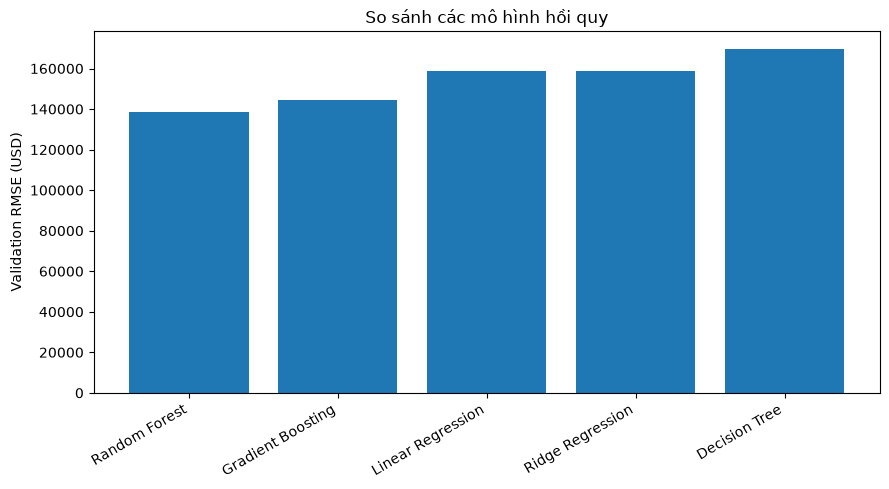

In [25]:
display(validation_results.style.format({
    "MAE": "${:,.0f}",
    "MSE": "{:,.0f}",
    "RMSE": "${:,.0f}",
    "R2": "{:.4f}",
    "Thời gian huấn luyện (s)": "{:.3f}"
}))

plt.figure(figsize=(9, 5))
plt.bar(validation_results["Model"], validation_results["RMSE"])
plt.ylabel("Validation RMSE (USD)")
plt.title("So sánh các mô hình hồi quy")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [26]:
best_model_name = validation_results.iloc[0]["Model"]
best_validation_rmse = validation_results.iloc[0]["RMSE"]

print("Mô hình tốt nhất trên validation:", best_model_name)
print(f"Validation RMSE: ${best_validation_rmse:,.2f}")

Mô hình tốt nhất trên validation: Random Forest
Validation RMSE: $138,336.01


# 19. Đánh giá mô hình

Sau khi lựa chọn mô hình bằng tập validation, mô hình được chọn sẽ được huấn luyện lại bằng **training + validation**.

Tập test vẫn hoàn toàn chưa được sử dụng cho đến bước đánh giá cuối cùng này.

Các chỉ số hồi quy:

- MAE càng thấp càng tốt;
- MSE/RMSE càng thấp càng tốt;
- \(R^2\) càng cao càng tốt;
- RMSE và MAE có thể được diễn giải trực tiếp theo thang giá nhà.

In [27]:
# Chỉ gộp train và validation sau khi đã lựa chọn mô hình
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

# Build a fresh pipeline using the selected estimator
selected_estimator = clone(model_estimators[best_model_name])

final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", selected_estimator)
])

start = time.perf_counter()
final_model.fit(X_train_final, y_train_final)
final_training_time = time.perf_counter() - start

test_pred = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_pred)
test_mse = mean_squared_error(y_test, test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_pred)

test_results = pd.DataFrame([{
    "Mô hình được chọn": best_model_name,
    "MAE": test_mae,
    "MSE": test_mse,
    "RMSE": test_rmse,
    "R2": test_r2,
    "Thời gian huấn luyện cuối (s)": final_training_time
}])

display(test_results.style.format({
    "MAE": "${:,.0f}",
    "MSE": "{:,.0f}",
    "RMSE": "${:,.0f}",
    "R2": "{:.4f}",
    "Thời gian huấn luyện cuối (s)": "{:.3f}"
}))

,Mô hình được chọn,MAE,MSE,RMSE,R2,Thời gian huấn luyện cuối (s)
0,Random Forest,"$75,906","21,625,665,121","$147,057",0.8626,1.762


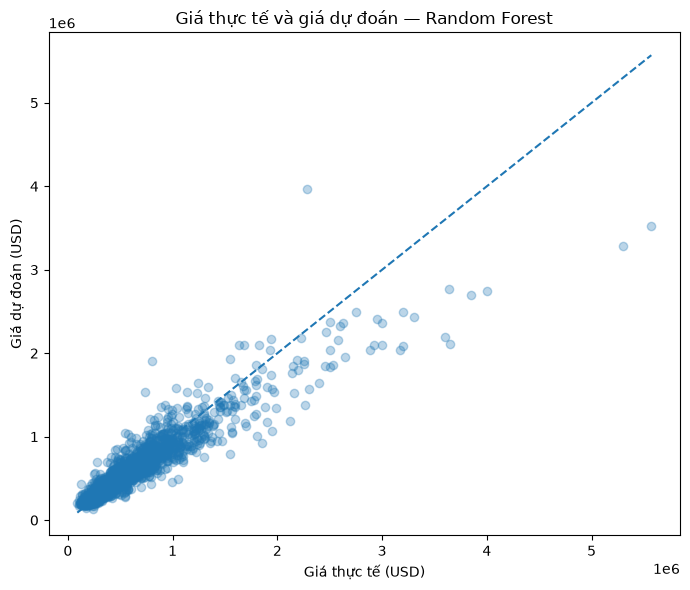

In [28]:
# Giá thực tế so với giá dự đoán
plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_pred, alpha=0.3)

min_val = min(y_test.min(), test_pred.min())
max_val = max(y_test.max(), test_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Giá thực tế (USD)")
plt.ylabel("Giá dự đoán (USD)")
plt.title(f"Giá thực tế và giá dự đoán — {best_model_name}")
plt.tight_layout()
plt.show()

### Diễn giải đánh giá cuối cùng

Các chỉ số trên tập test phản ánh hiệu năng của mô hình đối với dữ liệu không tham gia vào việc fit tiền xử lý, huấn luyện mô hình hay lựa chọn mô hình.

- **MAE = 75,906 USD**: trung bình dự đoán lệch khoảng 75.9 nghìn USD.
- **RMSE = 147,057 USD**: cho thấy vẫn tồn tại một số trường hợp dự đoán sai khá lớn.
- **R² = 0.8626**: mô hình giải thích được khoảng **86.26% biến thiên của giá nhà**.
- **Thời gian huấn luyện ≈ 1.76 giây**: chi phí tính toán hợp lý.

# 20. Phân tích lỗi

Các chỉ số tổng hợp không cho biết mô hình sai ở những trường hợp nào.

Phân tích lỗi bao gồm:

- phân bố residual;
- residual so với giá dự đoán;
- các trường hợp có sai số tuyệt đối lớn nhất;
- kiểm tra xem nhóm nhà đắt tiền có khó dự đoán hơn một cách có hệ thống hay không.

Bước này quan trọng vì một mô hình có thể có chỉ số trung bình khá tốt nhưng vẫn mắc sai số rất lớn ở một số phân khúc thị trường.

In [29]:
error_df = X_test.copy()
error_df["actual_price"] = y_test.values
error_df["predicted_price"] = test_pred
error_df["residual"] = error_df["actual_price"] - error_df["predicted_price"]
error_df["absolute_error"] = np.abs(error_df["residual"])
error_df["absolute_percentage_error"] = (
    error_df["absolute_error"] / error_df["actual_price"] * 100
)

display(
    error_df[
        ["actual_price", "predicted_price", "residual",
         "absolute_error", "absolute_percentage_error"]
    ]
    .sort_values("absolute_error", ascending=False)
    .head(10)
)

,actual_price,predicted_price,residual,absolute_error,absolute_percentage_error
4411,"5,570,000.000","3,522,413.000","2,047,587.000","2,047,587.000",36.761
1315,"5,300,000.000","3,287,286.000","2,012,714.000","2,012,714.000",37.976
12777,"2,280,000.000","3,965,284.100","-1,685,284.100","1,685,284.100",73.916
18482,"3,650,000.000","2,105,338.000","1,544,662.000","1,544,662.000",42.320
2864,"3,600,000.000","2,190,364.000","1,409,636.000","1,409,636.000",39.157
4149,"4,000,000.000","2,743,390.000","1,256,610.000","1,256,610.000",31.415
2085,"3,850,000.000","2,696,507.900","1,153,492.100","1,153,492.100",29.961
13528,"3,168,750.000","2,034,104.000","1,134,646.000","1,134,646.000",35.807
11535,"3,200,000.000","2,086,276.700","1,113,723.300","1,113,723.300",34.804
4024,"800,000.000","1,904,803.260","-1,104,803.260","1,104,803.260",138.100


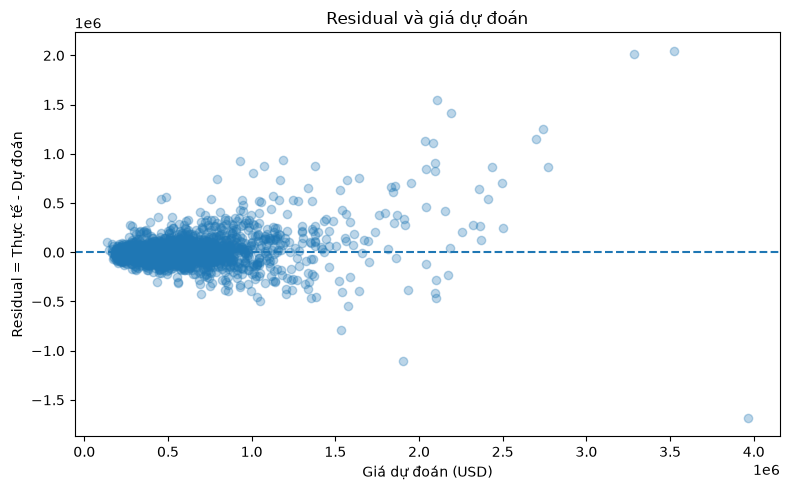

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(error_df["predicted_price"], error_df["residual"], alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Giá dự đoán (USD)")
plt.ylabel("Residual = Thực tế - Dự đoán")
plt.title("Residual và giá dự đoán")
plt.tight_layout()
plt.show()

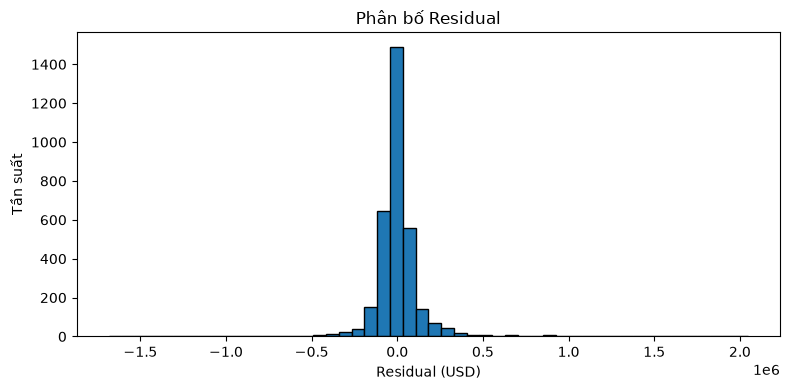

In [31]:
plt.figure(figsize=(8, 4))
plt.hist(error_df["residual"], bins=50, edgecolor="black")
plt.xlabel("Residual (USD)")
plt.ylabel("Tần suất")
plt.title("Phân bố Residual")
plt.tight_layout()
plt.show()

In [32]:
# So sánh sai số theo tứ phân vị của giá thực tế
error_df["price_quartile"] = pd.qcut(
    error_df["actual_price"],
    q=4,
    labels=["Q1 - Thấp nhất", "Q2", "Q3", "Q4 - Cao nhất"]
)

error_by_segment = (
    error_df.groupby("price_quartile", observed=True)
    .agg(
        observations=("actual_price", "size"),
        mean_actual_price=("actual_price", "mean"),
        MAE=("absolute_error", "mean"),
        median_APE=("absolute_percentage_error", "median")
    )
)

display(error_by_segment)

,observations,mean_actual_price,MAE,median_APE
price_quartile,,,,
Q1 - Thấp nhất,813,"253,475.728","43,430.937",12.141
Q2,819,"385,184.447","43,213.066",8.110
Q3,800,"543,853.363","58,661.870",7.951
Q4 - Cao nhất,810,"1,023,046.177","158,588.020",10.731


### Diễn giải phân tích lỗi

Cần đặc biệt chú ý đến nhóm 25% căn nhà có giá cao nhất.

Nếu sai số tuyệt đối tăng mạnh ở nhóm này, các nguyên nhân có thể gồm:

- số lượng mẫu nhà hạng sang ít hơn;
- ảnh hưởng vị trí mang tính đặc thù;
- tương tác mạnh giữa `grade`, `view`, `waterfront` và vị trí;
- độ biến thiên lớn hơn ở phần đuôi trên của phân bố giá.

Các hiện tượng này cần được phân tích thay vì tự động xóa những quan sát khó dự đoán.

# 21. Lựa chọn mô hình

Mô hình để triển khai được lựa chọn dựa trên **hiệu năng validation**, không dựa trên hiệu năng test.

Tiêu chí lựa chọn:

1. validation RMSE;
2. MAE và \(R^2\);
3. khả năng xử lý quan hệ phi tuyến;
4. chi phí huấn luyện/inference;
5. khả năng lưu và triển khai thuận tiện.

Tập test chỉ được sử dụng sau khi quyết định lựa chọn mô hình đã hoàn tất.

Pipeline được lựa chọn chứa đồng thời:

- bước tiền xử lý;
- mô hình hồi quy đã huấn luyện.

Điều này rất quan trọng vì giai đoạn triển khai phải tái tạo chính xác biểu diễn dữ liệu đã được sử dụng trong quá trình huấn luyện.

In [33]:
best_row = validation_results.iloc[0]

print("Mô hình được chọn:", best_model_name)
print(f"Validation MAE:  ${best_row['MAE']:,.2f}")
print(f"Validation RMSE: ${best_row['RMSE']:,.2f}")
print(f"Validation R²:   {best_row['R2']:.4f}")

print("\nHiệu năng cuối cùng trên tập test:")
print(f"Test MAE:  ${test_mae:,.2f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R²:   {test_r2:.4f}")

Mô hình được chọn: Random Forest
Validation MAE:  $73,678.90
Validation RMSE: $138,336.01
Validation R²:   0.8499

Hiệu năng cuối cùng trên tập test:
Test MAE:  $75,905.81
Test RMSE: $147,056.67
Test R²:   0.8626


### Mẫu giải thích lý do lựa chọn mô hình

Sử dụng kết quả thực tế ở cell phía trên để hoàn thiện phần báo cáo:

> Mô hình được lựa chọn để triển khai là **Random Forest** vì đạt validation RMSE thấp nhất, đồng thời duy trì MAE và \(R^2\) cạnh tranh. Quyết định lựa chọn được thực hiện trước khi xem kết quả đánh giá cuối cùng trên tập test. Sau đó mô hình được huấn luyện lại trên tập training kết hợp validation và chỉ được đánh giá một lần trên tập test độc lập. Toàn bộ logic tiền xử lý và mô hình hồi quy được lưu trong một pipeline duy nhất, giúp hệ thống có khả năng tái lập và thuận lợi cho triển khai.

# 22. Lưu mô hình

Pipeline cuối cùng phải có thể tái sử dụng mà không cần huấn luyện lại.

Đối tượng được lưu chứa:

- numerical imputation;
- numerical scaling;
- categorical imputation;
- one-hot encoding;
- mô hình hồi quy đã được lựa chọn và huấn luyện.

Việc lưu toàn bộ pipeline giúp tránh một lỗi triển khai phổ biến: API áp dụng tiền xử lý khác với tiền xử lý đã sử dụng trong notebook.

In [34]:
MODEL_DIR = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "house_price_pipeline.joblib")
joblib.dump(final_model, MODEL_PATH)

print("Đã lưu pipeline mô hình tại:", MODEL_PATH)
print("Tệp đã tồn tại:", os.path.exists(MODEL_PATH))

Đã lưu pipeline mô hình tại: model\house_price_pipeline.joblib
Tệp đã tồn tại: True


In [35]:
# Tải lại ngay để kiểm tra việc lưu mô hình.
loaded_model = joblib.load(MODEL_PATH)

reload_pred = loaded_model.predict(X_test.iloc[:5])

verification = pd.DataFrame({
    "du_doan_pipeline_goc": final_model.predict(X_test.iloc[:5]),
    "du_doan_pipeline_tai_lai": reload_pred
})

verification["chenh_lech"] = (
    verification["du_doan_pipeline_goc"]
    - verification["du_doan_pipeline_tai_lai"]
)

display(verification)

,du_doan_pipeline_goc,du_doan_pipeline_tai_lai,chenh_lech
0,"333,729.480","333,729.480",0.000
1,"2,696,507.900","2,696,507.900",0.000
2,"520,814.380","520,814.380",0.000
3,"280,361.630","280,361.630",0.000
4,"370,403.750","370,403.750",0.000


# 23. Kiểm thử suy luận (Inference Test)

Bước cuối của notebook mô phỏng giai đoạn triển khai:

\[
\text{Dữ liệu người dùng thô}
\rightarrow
\text{Kiểm tra / Feature Engineering}
\rightarrow
\text{Tiền xử lý đã lưu}
\rightarrow
\text{Mô hình đã lưu}
\rightarrow
\text{Giá nhà dự đoán}
\]

API hoặc ứng dụng mobile **không được fit lại scaler, encoder hoặc model** từ dữ liệu đầu vào của người dùng.

Hệ thống phải tải pipeline đã lưu và áp dụng chính xác các phép tiền xử lý đã học trong quá trình huấn luyện.

Vì feature engineering trong notebook này được thực hiện trước pipeline scikit-learn, code triển khai cũng phải gọi cùng hàm `engineer_features()` trước khi chạy `loaded_model.predict()`.

In [36]:
# Mô phỏng một bản ghi thô được gửi từ web/mobile client.
raw_inference_example = df.drop(columns=["price"]).iloc[[0]].copy()

print("Đầu vào thô:")
display(raw_inference_example)

# Apply exactly the same semantic feature engineering
engineered_inference_example = engineer_features(raw_inference_example)

print("Đầu vào mô hình sau feature engineering:")
display(engineered_inference_example)

# Load the persisted pipeline and predict
deployed_model = joblib.load(MODEL_PATH)
predicted_price = deployed_model.predict(engineered_inference_example)[0]

print(f"Giá nhà dự đoán: ${predicted_price:,.2f}")

Đầu vào thô:


,id,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,3,1.000,1180,5650,1.000,0,0,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650


Đầu vào mô hình sau feature engineering:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,years_since_renovation
0,3,1.000,1180,5650,1.000,0,0,3,7,1180,0,98178,47.511,-122.257,1340,5650,2014,10,59,0,0


Giá nhà dự đoán: $255,240.90


In [37]:
# Hàm hỗ trợ dự đoán thuận tiện cho triển khai

def predict_house_price(raw_input: dict, model_path=MODEL_PATH):
    # 1. Chuyển đầu vào dạng JSON thành DataFrame
    input_df = pd.DataFrame([raw_input])

    # 2. Áp dụng đúng feature engineering đã dùng khi xây dựng mô hình
    input_features = engineer_features(input_df)

    # 3. Tải pipeline tiền xử lý + mô hình đã lưu
    model = joblib.load(model_path)

    # 4. Dự đoán
    prediction = model.predict(input_features)[0]

    return {
        "predicted_price": round(float(prediction), 2)
    }


example_request = raw_inference_example.iloc[0].to_dict()
example_response = predict_house_price(example_request)

print("Ví dụ phản hồi:")
print(example_response)

Ví dụ phản hồi:
{'predicted_price': 255240.9}
